In [1]:
import numpy as np 
import pandas as pd
import scanpy as sc 
import os 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.metrics import euclidean_distances

In [ ]:
scdata = sc.read_h5ad('../data/final_anno.h5ad')
scdata

## DEG PLOT FOR 7 celltype

In [ ]:
## 在每一个脑区下计算 6 个细胞类型的DEG matrix plot

all_res = []
gene_list = scdata.raw.var.index
for key in scdata.obs.tissues.unique():
    adata = scdata[scdata.obs.tissues == key]
    sc.tl.rank_genes_groups(adata, 'celltype')

    tissue_res = {}

    for cell in scdata.obs.celltype.unique():
        df = sc.get.rank_genes_groups_df(adata, group = [cell])
        df.index = df['names'].values 
        df = df.loc[gene_list,:]
        tissue_res[cell] = df['logfoldchanges'].values 

    tissue_df = pd.DataFrame(tissue_res)
    new_col = [f'{col}:{key}' for col in tissue_df.columns]
    tissue_df.columns = new_col
    all_res.append(tissue_df)


final_df = pd.concat(all_res, axis = 1)
final_df.index = gene_list
print(final_df.shape)

In [20]:
marker_dic = {
    'inhibitory neuron': ['Gad1'],
    'excitatory neuron': ['Slc17a7'],
    'oligodendrocyte': ['Mobp'],
    'OPC': ['Pdgfra'],
    'astrocyte': ['Slc15a2'],
    'ependymal': ['Spef2'],
    'microglia': ['Cx3cr1'],}


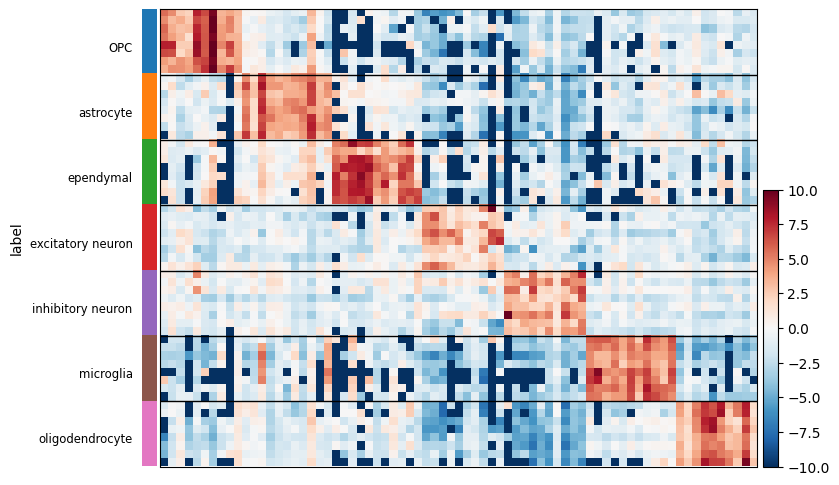

In [ ]:
import anndata as ad
new_col = []
for key in scdata.obs.celltype.unique():
    for key2 in ['BQ','YB','PC','HM','NG','QN', 'CT','XQ']:
        new_col.append(f'{key}:{key2}')

final_df = final_df.loc[:,new_col].T 
final_df.columns = gene_list 
print(final_df.shape) 

adata = ad.AnnData(final_df.values, )
adata.obs.index = final_df.index
adata.var_names = gene_list

new_label = []
for key in scdata.obs.celltype.unique():
    new_label += [key]*8
adata.obs.loc[:,'label'] = new_label

sc.tl.rank_genes_groups(adata, groupby= 'label', method = 'wilcoxon')

'''get group marker gene'''
cell_list = [ 'OPC','astrocyte','ependymal','excitatory neuron','inhibitory neuron','microglia','oligodendrocyte',]
gene_array = []
for key in cell_list:
    df =sc.get.rank_genes_groups_df(adata, [key])
    gene_array += list(df['names'][:10].values) 

    if marker_dic[key][0] not in df['names'][:10].values:
        gene_array += [marker_dic[key][0]]

sc.pl.heatmap(adata, var_names = gene_array, groupby = 'label', cmap = 'RdBu_r',vmin = -10, vmax = 10)
# sc.pl.rank_genes_groups_heatmap(adata, n_genes=10,  dendrogram=False, cmap = 'RdBu_r',vmax = 12, vmin = -10, figsize = (15,8),show_gene_labels=True, show = False)
#plt.savefig('matrix_plot_7cell.pdf', bbox_inches='tight')

## PLOT THE LOG2FC value in deg heatmap

In [29]:
map_dic = {'CY': 'eco',
           'JT': 'eco',
           'T': 'eco',
           'QF': 'neco',
           'M': 'neco'}
scdata.obs.loc[:,'eco'] = scdata.obs.species.map(map_dic)

In [ ]:
## 在每一个脑区下计算 6 个细胞类型的DEG matrix plot

all_res = []
gene_list = scdata.raw.var.index
for key in scdata.obs.tissues.unique():
    adata = scdata[scdata.obs.tissues == key]
    idx = adata.obs.eco == 'eco'
    adata = adata[idx,:]
    sc.tl.rank_genes_groups(adata, 'celltype')

    tissue_res = {}

    for cell in scdata.obs.celltype.unique():
        df = sc.get.rank_genes_groups_df(adata, group = [cell])
        df.index = df['names'].values 
        df = df.loc[gene_list,:]
        tissue_res[cell] = df['logfoldchanges'].values 

    tissue_df = pd.DataFrame(tissue_res)
    new_col = [f'eco-{col}:{key}' for col in tissue_df.columns]
    tissue_df.columns = new_col
    all_res.append(tissue_df)


eco_df = pd.concat(all_res, axis = 1)
eco_df.index = gene_list


In [ ]:
## 在每一个脑区下计算 6 个细胞类型的DEG matrix plot

all_res = []
gene_list = scdata.raw.var.index
for key in scdata.obs.tissues.unique():
    adata = scdata[scdata.obs.tissues == key]
    idx = adata.obs.eco == 'neco'
    adata = adata[idx,:]
    sc.tl.rank_genes_groups(adata, 'celltype')

    tissue_res = {}

    for cell in scdata.obs.celltype.unique():
        df = sc.get.rank_genes_groups_df(adata, group = [cell])
        df.index = df['names'].values 
        df = df.loc[gene_list,:]
        tissue_res[cell] = df['logfoldchanges'].values 

    tissue_df = pd.DataFrame(tissue_res)
    new_col = [f'neco-{col}:{key}' for col in tissue_df.columns]
    tissue_df.columns = new_col
    all_res.append(tissue_df)


neco_df = pd.concat(all_res, axis = 1)
neco_df.index = gene_list
print(neco_df.shape)

In [36]:
final_df = pd.concat([eco_df, neco_df], axis = 1)
final_df.to_csv('logfc_gene.csv')

In [ ]:
final_df

In [ ]:

import anndata as ad
new_col = []
for key in scdata.obs.celltype.unique():
    for key2 in ['BQ','YB','PC','HM','NG','QN', 'CT','XQ']:
        new_col.append(f'eco-{key}:{key2}')
        new_col.append(f'neco-{key}:{key2}')

final_df = final_df.loc[:,new_col].T 
final_df.columns = gene_list 
print(final_df.shape) 

adata = ad.AnnData(final_df.values, )
adata.obs.index = final_df.index
adata.var_names = gene_list

new_label = []
for key in scdata.obs.celltype.unique():
    new_label += [key]*16
adata.obs.loc[:,'label'] = new_label
sc.pl.heatmap(adata, var_names = gene_array, groupby = 'label', cmap = 'RdBu_r',vmin = -10, vmax = 10)
# sc.pl.rank_genes_groups_heatmap(adata, n_genes=10,  dendrogram=False, cmap = 'RdBu_r',vmax = 12, vmin = -10, figsize = (15,8),show_gene_labels=True, show = False)
#plt.savefig('matrix_plot_7cell.pdf', bbox_inches='tight')


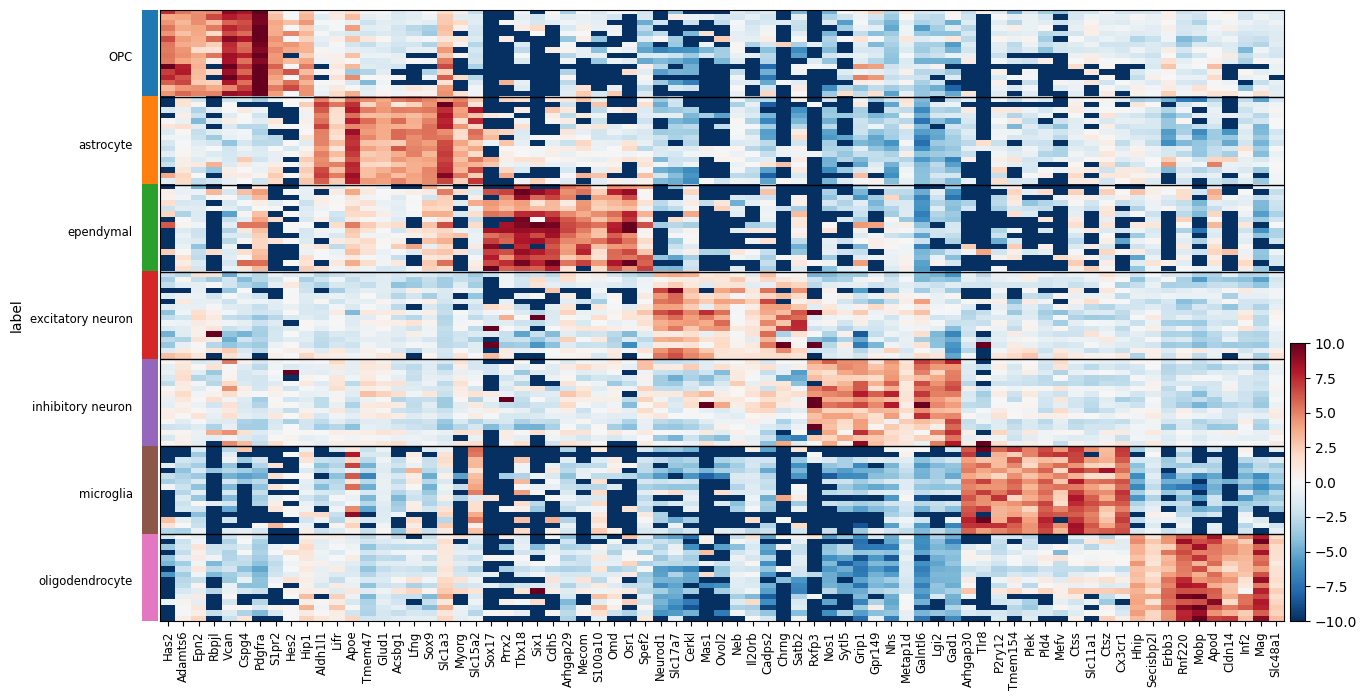

In [42]:
sc.pl.heatmap(adata, var_names = gene_array, groupby = 'label', cmap = 'RdBu_r',vmin = -10, vmax = 10, show = False, figsize=(15,8), show_gene_labels=True)
plt.savefig('heatmap.pdf', bbox_inches='tight', dpi = 600)

In [44]:
final_df.to_csv('gene_logfc.csv')


In [45]:
with open('gene.txt', 'w') as f:
    for ele in gene_array:
        f.write(ele + '\n')